BASE_DIR: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-


,H,I,D
H,-0.121514,0.103529,0.017985
I,0.245058,-0.312340,0.067282
D,0.000000,0.000000,0.000000


Saved: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part3a_generator_matrix_Q.csv
Row sums of Q: [3.46944695e-18 1.38777878e-17 0.00000000e+00]
All off-diagonals >= 0: True
Saved: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part3a_markov_state_diagram.png


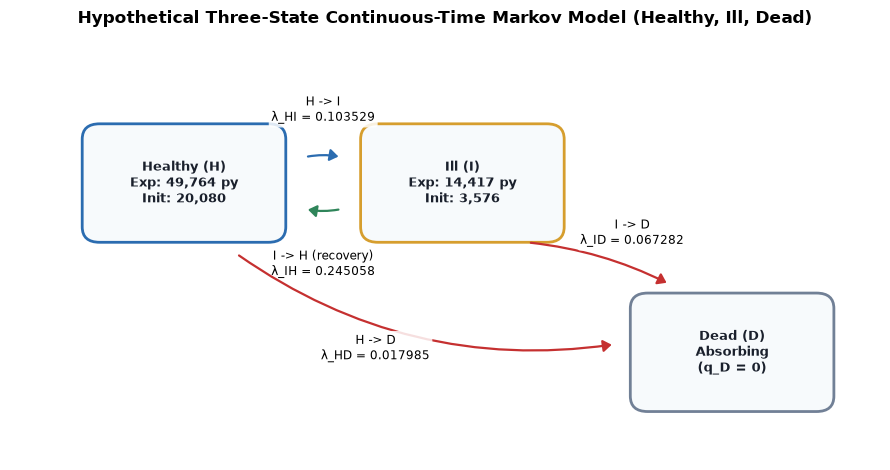

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

%matplotlib inline

# ---------- Paths ----------
def find_base_dir():
    env = os.environ.get("PROJECT_DIR")
    if env and (Path(env) / "data" / "raw").exists():
        return Path(env)
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "raw").exists():
            return p
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        chosen = filedialog.askdirectory(title="Select the project folder (the one containing data/raw)")
        root.destroy()
    except Exception:
        chosen = input("Paste the project folder path: ").strip().strip('"')
    if chosen and (Path(chosen) / "data" / "raw").exists():
        return Path(chosen)
    raise FileNotFoundError("data/raw not found in the selected folder.")

BASE_DIR = find_base_dir()
RAW_DIR = BASE_DIR / "data" / "raw"
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("BASE_DIR:", BASE_DIR)

def safe_save(save_fn, filename):
    try:
        save_fn(OUT_DIR / filename)
        print("Saved:", OUT_DIR / filename)
    except OSError as e:
        fallback = Path.home() / "part3a_outputs"
        fallback.mkdir(exist_ok=True)
        save_fn(fallback / filename)
        print("Could not write to", OUT_DIR, "-", e)
        print("Saved to", fallback / filename, "instead.")

# ---------- Data ----------
ins = pd.read_csv(RAW_DIR / "insured_transitions.csv")

# 1. Deduplicate repeated (district_id, origin) exposure_py and initial_lives per README.txt
unique_origin = ins.drop_duplicates(subset=["district_id", "origin"])[
    ["district_id", "origin", "exposure_py", "initial_lives"]
]
pooled_exp = unique_origin.groupby("origin")["exposure_py"].sum().to_dict()
pooled_init = unique_origin.groupby("origin")["initial_lives"].sum().to_dict()
pooled_jumps = ins.groupby(["origin", "destination"])["transition_count"].sum().to_dict()

# 2. Transition intensities per origin-state person-year
lam_HI = pooled_jumps[("H", "I")] / pooled_exp["H"]
lam_HD = pooled_jumps[("H", "D")] / pooled_exp["H"]
lam_IH = pooled_jumps[("I", "H")] / pooled_exp["I"]
lam_ID = pooled_jumps[("I", "D")] / pooled_exp["I"]

# 3. Generator matrix Q in order H, I, D
Q = np.array([
    [-(lam_HI + lam_HD),  lam_HI,            lam_HD],
    [ lam_IH,            -(lam_IH + lam_ID),  lam_ID],
    [ 0.0,                0.0,               0.0]
], dtype=float)

q_df = pd.DataFrame(Q, index=["H", "I", "D"], columns=["H", "I", "D"])
display(q_df)
safe_save(lambda p: q_df.to_csv(p), "part3a_generator_matrix_Q.csv")
print("Row sums of Q:", Q.sum(axis=1))
print("All off-diagonals >= 0:", bool((Q[~np.eye(3, dtype=bool)] >= 0).all()))

# 4. State diagram
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5.5)
ax.axis("off")

pos = {"H": (2.0, 3.6), "I": (5.2, 3.6), "D": (8.3, 1.4)}
labels = {
    "H": f"Healthy (H)\nExp: {pooled_exp['H']:,} py\nInit: {pooled_init['H']:,}",
    "I": f"Ill (I)\nExp: {pooled_exp['I']:,} py\nInit: {pooled_init['I']:,}",
    "D": "Dead (D)\nAbsorbing\n(q_D = 0)"
}
colors = {"H": "#2b6cb0", "I": "#d69e2e", "D": "#718096"}

for st, (x, y) in pos.items():
    box = mpatches.FancyBboxPatch((x - 1.05, y - 0.65), 2.1, 1.3,
                                  boxstyle="round,pad=0.12,rounding_size=0.2",
                                  linewidth=2, edgecolor=colors[st], facecolor="#f7fafc")
    ax.add_patch(box)
    ax.text(x, y, labels[st], ha="center", va="center", fontsize=9.5, fontweight="bold", color="#1a202c")

def draw_arrow(p1, p2, rad, text, text_pos, color="#1a202c"):
    ax.annotate("", xy=p2, xytext=p1,
                arrowprops=dict(arrowstyle="-|>,head_width=0.35,head_length=0.5",
                                lw=1.6, color=color, shrinkA=18, shrinkB=18,
                                connectionstyle=f"arc3,rad={rad}"))
    ax.text(text_pos[0], text_pos[1], text, ha="center", va="center", fontsize=8.8,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85))

draw_arrow((3.15, 3.85), (4.05, 3.85), -0.22, f"H -> I\nλ_HI = {lam_HI:.6f}", (3.6, 4.55), "#2b6cb0")
draw_arrow((4.05, 3.35), (3.15, 3.35), -0.22, f"I -> H (recovery)\nλ_IH = {lam_IH:.6f}", (3.6, 2.55), "#2f855a")
draw_arrow((2.4, 2.85), (7.2, 1.55), 0.22, f"H -> D\nλ_HD = {lam_HD:.6f}", (4.2, 1.45), "#c53030")
draw_arrow((5.7, 2.85), (7.8, 2.15), -0.12, f"I -> D\nλ_ID = {lam_ID:.6f}", (7.15, 2.95), "#c53030")

ax.set_title("Hypothetical Three-State Continuous-Time Markov Model (Healthy, Ill, Dead)",
             fontsize=12, fontweight="bold", pad=10)
plt.tight_layout()
safe_save(lambda p: fig.savefig(p, dpi=150), "part3a_markov_state_diagram.png")
plt.show()